# Q-transform + FFT around a trigger (single `.mseed` file)

Give a trigger time (UTC) and the notebook shows the waveform, the Q-transform and the FFT amplitude spectrum around it.
If `TRIGGER_TIME = None`, the trigger is taken from the recursive STA/LTA instead.

Requires `obspy`, `gwpy`, `numpy`, `matplotlib`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from gwpy.segments import Segment
from gwpy.timeseries import TimeSeries
from obspy import UTCDateTime, read
from obspy.signal.trigger import recursive_sta_lta, trigger_onset

plt.rcParams.update({"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13})

## Parameters

In [2]:
FILE    = "year_Virgo_data/2022/VRG01_HH3_2022-01-15.mseed"
CHANNEL = None            # e.g. "HH1" if the file contains several channels

# --- Trigger -----------------------------------------------------------
TRIGGER_TIME = None  # UTC; set to None to detect it with STA/LTA
# used only when TRIGGER_TIME is None
STA, LTA   = 0.5, 20.0    # seconds
THR_ON     = 20.0
THR_OFF    = 1.5
TRIGGER_INDEX = 0         # which detected trigger to use (see the printed list)

# --- Window around the trigger (s) ---------------------------------------
HALF_WIDTH = 12.0         # waveform and Q-transform are shown for +-HALF_WIDTH
PAD        = 10.0         # extra data on each side given to the Q-transform (avoids edge effects)

# --- Optional filter applied to the data before everything (Hz) ----------
FMIN = 2.0
FMAX = 30.0

# --- Q-transform ----------------------------------------------------------
QRANGE = (10, 32)
FRANGE = None             # (fmin, fmax) in Hz; None -> let gwpy choose
TRES   = 0.05             # time resolution (s)
NORM   = "median"         # "median", "mean" or None (raw energy)
LOGF   = True
CMAP   = "viridis"
INTENSITY_THRESHOLD = None   # colour saturation; None -> 99.5th percentile

# --- FFT ------------------------------------------------------------------
FFT_HALF_WIDTH = 2.0      # FFT of the data within +-FFT_HALF_WIDTH of the trigger
BG_OFFSET      = None     # e.g. 30 -> also plot a background FFT centred 30 s before the trigger

# --- Output -----------------------------------------------------------------
OUT_DIR = "."
DPI     = 300

## Load

In [3]:
st = read(FILE)
if CHANNEL:
    st = st.select(channel=CHANNEL)
assert len(st) > 0, "No traces found (check CHANNEL)."

# Join segments of the same id; small gaps are interpolated
st.merge(method=1, fill_value="interpolate")
if len(st) > 1:
    print(f"File has {len(st)} traces, using the first one: {[t.id for t in st]}. Set CHANNEL to pick another.")

tr = st[0].copy()          # copy, so re-running this cell never filters twice
fs = tr.stats.sampling_rate
print(f"{tr.id} | {tr.stats.starttime} -> {tr.stats.endtime} | {fs:g} Hz | {tr.stats.npts} samples")

tr.detrend("demean")
if FMIN and FMAX:
    tr.filter("bandpass", freqmin=FMIN, freqmax=FMAX, corners=4, zerophase=True)
elif FMIN:
    tr.filter("highpass", freq=FMIN, corners=4, zerophase=True)
elif FMAX:
    tr.filter("lowpass", freq=FMAX, corners=4, zerophase=True)

VR.VRG01..HH3 | 2022-01-15T00:00:00.000000Z -> 2022-01-16T00:00:00.560000Z | 100 Hz | 8640057 samples


## Trigger

In [4]:
if TRIGGER_TIME is not None:
    trig = UTCDateTime(TRIGGER_TIME)
else:
    nsta, nlta = int(round(STA * fs)), int(round(LTA * fs))
    cft = recursive_sta_lta(tr.data.astype(np.float64), nsta, nlta)
    cft[:nlta] = 0.0
    onsets = trigger_onset(cft, THR_ON, THR_OFF)
    assert len(onsets) > 0, "No STA/LTA trigger found; lower THR_ON or change the windows."
    for i, (on, off) in enumerate(onsets[:20]):
        print(f"  [{i}] {tr.stats.starttime + on / fs}   peak STA/LTA = {cft[on:off + 1].max():.1f}")
    trig = tr.stats.starttime + onsets[TRIGGER_INDEX][0] / fs

print("Trigger:", trig)

# Cut the data around the trigger (with padding) and build a time axis relative to it
t_start = trig - (HALF_WIDTH + PAD)
t_end   = trig + (HALF_WIDTH + PAD)
assert t_start >= tr.stats.starttime and t_end <= tr.stats.endtime, (
    "Trigger too close to the file edges for this HALF_WIDTH + PAD; reduce them.")

seg   = tr.slice(t_start, t_end)
x     = seg.data.astype(np.float64)
t_rel = seg.times() + (seg.stats.starttime - trig)    # seconds since trigger

  [0] 2022-01-15T01:53:59.440000Z   peak STA/LTA = 20.4
  [1] 2022-01-15T20:56:20.580000Z   peak STA/LTA = 25.5
Trigger: 2022-01-15T01:53:59.440000Z


## Q-transform

In [5]:
ts = TimeSeries(x, sample_rate=fs, t0=t_rel[0])
spec = ts.q_transform(
    qrange=QRANGE,
    frange=FRANGE if FRANGE else (0, np.inf),
    tres=TRES,
    whiten=False,
    norm=NORM if NORM else False,
    logf=LOGF,
    outseg=Segment(-HALF_WIDTH, HALF_WIDTH),
)
spec_t = spec.times.value            # s since trigger
spec_f = spec.frequencies.value      # Hz
spec_z = spec.value                  # (time, frequency)
print("Q =", getattr(spec, "q", "n/a"), "| spectrogram shape:", spec_z.shape)

Q = 23.925580499539528 | spectrogram shape: (480, 500)


Saved: VRG01_HH3_2022-01-15_20220115T015359_qtransform.png


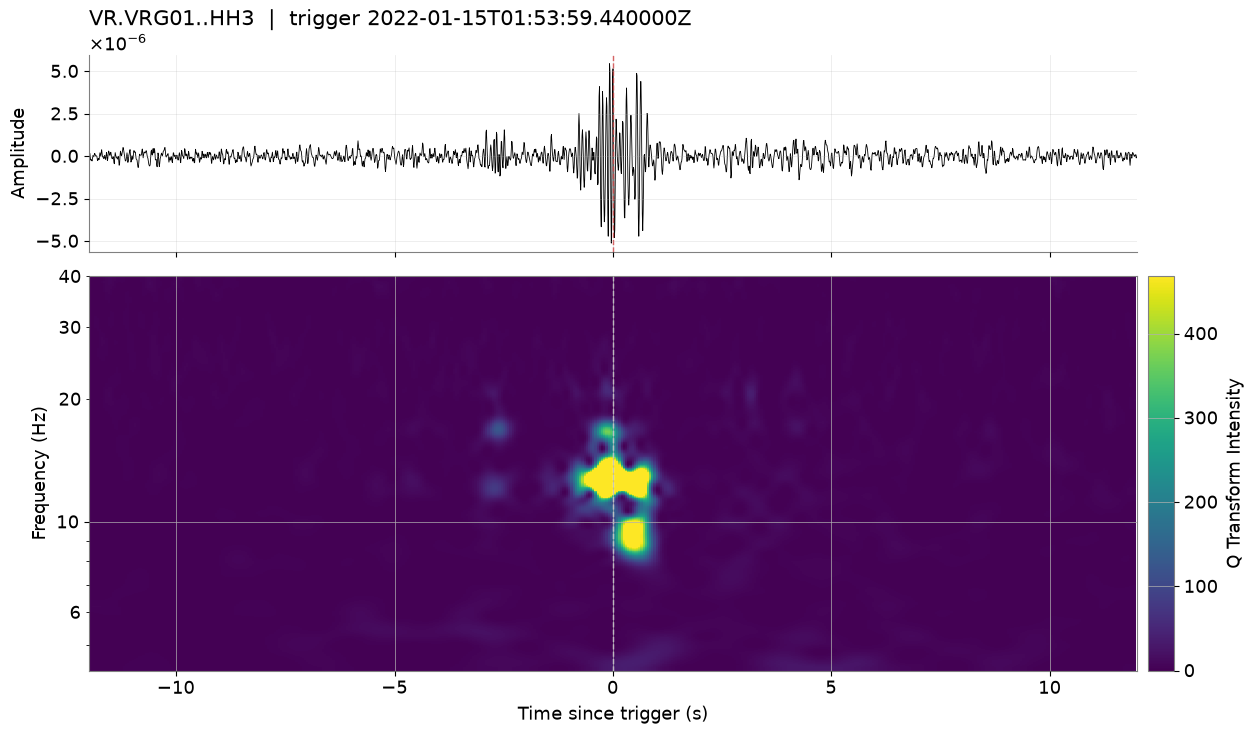

In [6]:
vmax = INTENSITY_THRESHOLD or np.percentile(spec_z, 99.5)
win = np.abs(t_rel) <= HALF_WIDTH

fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[40, 1], height_ratios=[1, 2], hspace=0.08, wspace=0.02)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
cax = fig.add_subplot(gs[1, 1])

ax1.plot(t_rel[win], x[win], color="black", lw=0.6)
ax1.set_ylabel("Amplitude")
ax1.set_title(f"{tr.id}  |  trigger {trig}", loc="left")
plt.setp(ax1.get_xticklabels(), visible=False)

mesh = ax2.pcolormesh(spec_t, spec_f, spec_z.T, cmap=CMAP, vmin=0, vmax=vmax,
                      shading="auto", rasterized=True)
ax2.set_yscale("log")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_xlabel("Time since trigger (s)")
cb = fig.colorbar(mesh, cax=cax)
cb.set_label("Q Transform Intensity" + (f" (saturation at {vmax:.2e})" if INTENSITY_THRESHOLD else ""))

for ax in (ax1, ax2):
    ax.axvline(0, color="white" if ax is ax2 else "tab:red", ls="--", lw=1.0, alpha=0.8)
ax1.set_xlim(-HALF_WIDTH, HALF_WIDTH)
ax1.grid(alpha=0.3)
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)

tag = trig.strftime("%Y%m%dT%H%M%S")
out_q = Path(OUT_DIR) / f"{Path(FILE).stem}_{tag}_qtransform.png"
fig.savefig(out_q, dpi=DPI, bbox_inches="tight")
print("Saved:", out_q)
plt.show()

## FFT

FFT over 4.01 s | peak at 12.72 Hz
Saved: VRG01_HH3_2022-01-15_20220115T015359_fft.png


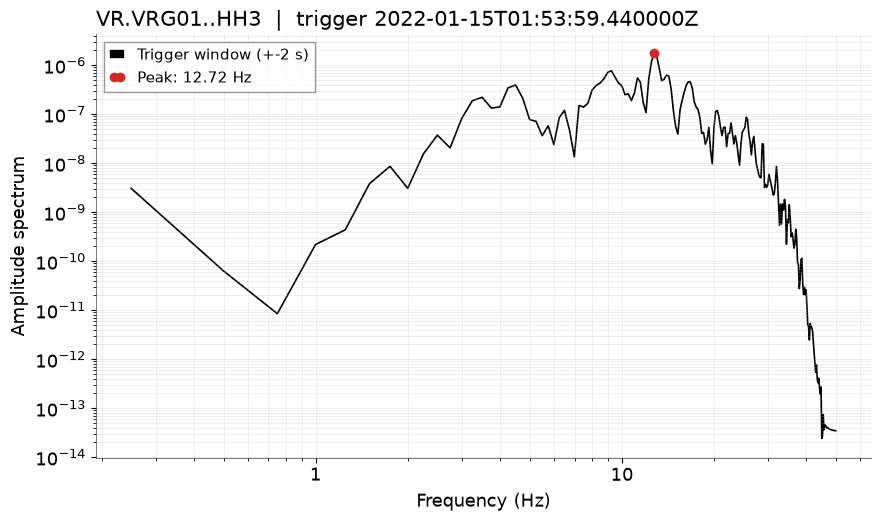

In [7]:
def amp_spectrum(sig, fs):
    """Single-sided amplitude spectrum of a Hann-tapered, demeaned signal."""
    w = np.hanning(len(sig))
    sig = (sig - sig.mean()) * w
    amp = np.abs(np.fft.rfft(sig)) * 2.0 / w.sum()
    f = np.fft.rfftfreq(len(sig), 1.0 / fs)
    return f[1:], amp[1:]          # drop the DC bin (log axes)


m = np.abs(t_rel) <= FFT_HALF_WIDTH
f, amp = amp_spectrum(x[m], fs)
f_peak = f[np.argmax(amp)]
print(f"FFT over {m.sum() / fs:.2f} s | peak at {f_peak:.2f} Hz")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.loglog(f, amp, color="black", lw=1.2, label=f"Trigger window (+-{FFT_HALF_WIDTH:g} s)")

if BG_OFFSET is not None:
    mb = np.abs(t_rel + BG_OFFSET) <= FFT_HALF_WIDTH
    if mb.sum() >= 0.9 * m.sum():
        fb, ampb = amp_spectrum(x[mb], fs)
        ax.loglog(fb, ampb, color="tab:gray", lw=1.2, label=f"Background ({BG_OFFSET:g} s before)")
    else:
        print("Not enough padded data for the background window; increase PAD or reduce BG_OFFSET.")

ax.plot(f_peak, amp.max(), "o", color="tab:red", label=f"Peak: {f_peak:.2f} Hz")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Amplitude spectrum")
ax.set_title(f"{tr.id}  |  trigger {trig}", loc="left")
ax.grid(alpha=0.3, which="both")
ax.legend(frameon=True, fontsize=11)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

out_f = Path(OUT_DIR) / f"{Path(FILE).stem}_{tag}_fft.png"
fig.savefig(out_f, dpi=DPI, bbox_inches="tight")
print("Saved:", out_f)
plt.show()

## FFT vs time (spectrogram)

Saved: VRG01_HH3_2022-01-15_20220115T015359_fft_spectrogram.png


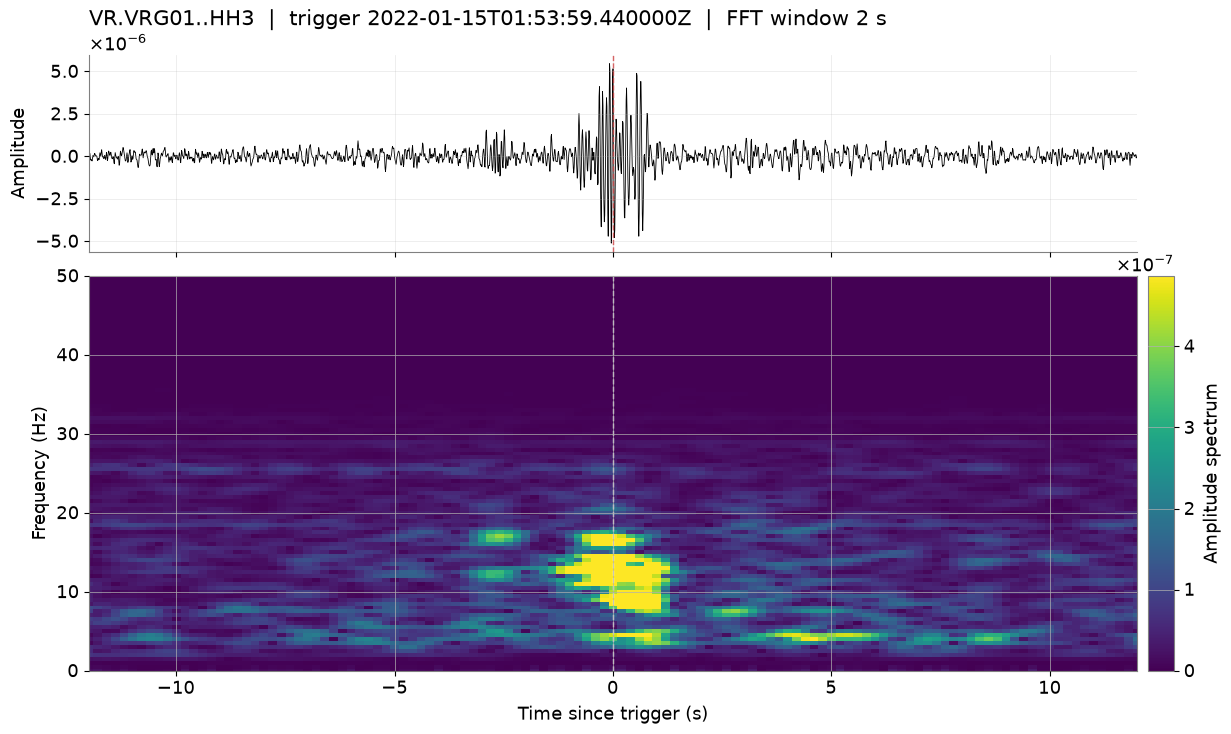

In [8]:
# Short-time FFT: sliding Hann-tapered windows, same amplitude scaling as the FFT cell above
SPEC_WIN     = 2.0      # window length (s): longer -> finer frequency resolution, coarser time resolution
SPEC_OVERLAP = 0.9      # fraction of overlap between consecutive windows
SPEC_FMIN    = 0.0      # Hz
SPEC_FMAX    = None     # Hz; None -> Nyquist
SPEC_LOGF    = False    # log frequency axis
SPEC_VMAX    = None     # colour saturation; None -> 99.5th percentile

nper = int(round(SPEC_WIN * fs))
hop  = max(1, int(round(nper * (1 - SPEC_OVERLAP))))
w    = np.hanning(nper)

frames = np.lib.stride_tricks.sliding_window_view(x, nper)[::hop]
frames = (frames - frames.mean(axis=1, keepdims=True)) * w
stft_a = np.abs(np.fft.rfft(frames, axis=1)) * 2.0 / w.sum()          # (time, frequency)
stft_f = np.fft.rfftfreq(nper, 1.0 / fs)
stft_t = t_rel[0] + (np.arange(len(frames)) * hop + nper / 2) / fs      # window centres, s since trigger

fmax = SPEC_FMAX or stft_f[-1]
fsel = (stft_f >= max(SPEC_FMIN, stft_f[1] if SPEC_LOGF else 0.0)) & (stft_f <= fmax)
vmax = SPEC_VMAX or np.percentile(stft_a[:, fsel], 99.5)
win  = np.abs(t_rel) <= HALF_WIDTH

fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[40, 1], height_ratios=[1, 2], hspace=0.08, wspace=0.02)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
cax = fig.add_subplot(gs[1, 1])

ax1.plot(t_rel[win], x[win], color="black", lw=0.6)
ax1.set_ylabel("Amplitude")
ax1.set_title(f"{tr.id}  |  trigger {trig}  |  FFT window {SPEC_WIN:g} s", loc="left")
plt.setp(ax1.get_xticklabels(), visible=False)

mesh = ax2.pcolormesh(stft_t, stft_f[fsel], stft_a[:, fsel].T, cmap=CMAP, vmin=0, vmax=vmax,
                      shading="auto", rasterized=True)
if SPEC_LOGF:
    ax2.set_yscale("log")
ax2.set_ylim(stft_f[fsel][0], stft_f[fsel][-1])
ax2.set_ylabel("Frequency (Hz)")
ax2.set_xlabel("Time since trigger (s)")
fig.colorbar(mesh, cax=cax).set_label("Amplitude spectrum")

for ax in (ax1, ax2):
    ax.axvline(0, color="white" if ax is ax2 else "tab:red", ls="--", lw=1.0, alpha=0.8)
ax1.set_xlim(-HALF_WIDTH, HALF_WIDTH)
ax1.grid(alpha=0.3)
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)

tag = trig.strftime("%Y%m%dT%H%M%S")
out_s = Path(OUT_DIR) / f"{Path(FILE).stem}_{tag}_fft_spectrogram.png"
fig.savefig(out_s, dpi=DPI, bbox_inches="tight")
print("Saved:", out_s)
plt.show()